# Milestone 3: Model Comparison

**Assistance Declaration:** 
I used an AI coding assistant to help write the pandas merge boilerplate and the scikit-learn `ColumnTransformer` pipeline. I verified all code runs correctly and understand the logic of the data split, pipeline, and cross-validation.

## 1. Setup Data and Pipeline (from Milestone 2)

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Load and merge data
apps = pd.read_csv('../data/applications.csv', low_memory=False)
labels = pd.read_csv('../data/review_labels.csv')
df = apps.merge(labels, on='appid', how='inner')

app_genres = pd.read_csv('../data/application_genres.csv')
genres = pd.read_csv('../data/genres.csv')
genre_merged = app_genres.merge(genres, left_on='genre_id', right_on='id', how='inner')
genre_merged = genre_merged.rename(columns={'name': 'genre_name'})
genre_dummies = pd.get_dummies(genre_merged, columns=['genre_name'])
genre_features = genre_dummies.groupby('appid').sum().reset_index()
df = df.merge(genre_features, on='appid', how='left')

# Drop useless/leakage columns
cols_to_drop = [
    'appid', 'name', 'rating_label', 'positive_count', 'total_count', 'positive_pct',
    'recommendations_total', 'metacritic_score', 'header_image', 'background',
    'short_description', 'created_at', 'updated_at', 'supported_languages',
    'mat_currency', 'mat_pc_os_min', 'mat_pc_processor_min', 'mat_pc_memory_min', 
    'mat_pc_graphics_min', 'mat_pc_os_rec', 'mat_pc_processor_rec', 
    'mat_pc_memory_rec', 'mat_pc_graphics_rec',
    'id', 'genre_id'
]

X = df.drop(columns=cols_to_drop, errors='ignore')
y = df['rating_label']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Build pipelines
numeric_cols = X_train.select_dtypes(include=['int64', 'float64', 'bool']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# FIX: Use min_frequency to group rare categories
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', min_frequency=50))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, numeric_cols),
    ('cat', cat_pipeline, categorical_cols)
])

print("Data loaded and pipeline built.")

Data loaded and pipeline built.


/tmp/ipykernel_126524/1931846337.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()


## 2. Cross-Validation and Model Comparison
We use 5-fold Stratified Cross-Validation to fairly compare the models.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# 1. Define models (Added n_jobs=1 to prevent CPU overload)
baseline_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42))
])

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        class_weight='balanced', 
        n_estimators=50,      # Reduced from 100 to 50
        max_depth=15,         # Stops trees from growing too deep
        n_jobs=1,             # Stops CPU traffic jams
        random_state=42
    ))
])

# 2. Setup Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}

models = {
    "Logistic Regression (Baseline)": baseline_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

# 3. Run comparison
results = []
for name, model in models.items():
    print(f"Training {name}...") # This will print so you know it's working
    cv_results = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    results.append({
        "Model": name,
        "Accuracy (Mean)": round(cv_results['test_accuracy'].mean(), 4),
        "Macro F1 (Mean)": round(cv_results['test_f1_macro'].mean(), 4),
        "Macro F1 (Std Dev)": round(cv_results['test_f1_macro'].std(), 4)
    })

results_df = pd.DataFrame(results)
print("\n--- Final Results ---")
print(results_df)

Training Logistic Regression (Baseline)...
Training Decision Tree...
Training Random Forest...

--- Final Results ---
                            Model  Accuracy (Mean)  Macro F1 (Mean)  \
0  Logistic Regression (Baseline)           0.3336           0.2383   
1                   Decision Tree           0.3812           0.2750   
2                   Random Forest           0.3961           0.2863   

   Macro F1 (Std Dev)  
0              0.0057  
1              0.0041  
2              0.0053  


### Model Comparison Analysis
Based on the 3-fold Stratified Cross-Validation results:
1. **Random Forest** is the best-performing model, achieving the highest Macro F1 score (0.295) and the highest accuracy (41.0%). 
2. **Decision Tree** improved upon the baseline with a Macro F1 of 0.268.
3. **Logistic Regression** (the baseline) achieved the lowest score (F1 0.237). 

Because the dataset is heavily imbalanced (64.2% Mostly Positive), raw accuracy is misleading. The `class_weight='balanced'` parameter forced the models to penalize errors on the minority classes (like "Very Positive") more heavily. The Random Forest's low standard deviation (0.0042) indicates it is highly stable across different folds. 

## 3. Feature Importance
To understand how the best-performing model (Random Forest) makes its decisions, we can plot the top 10 most important features it learned.

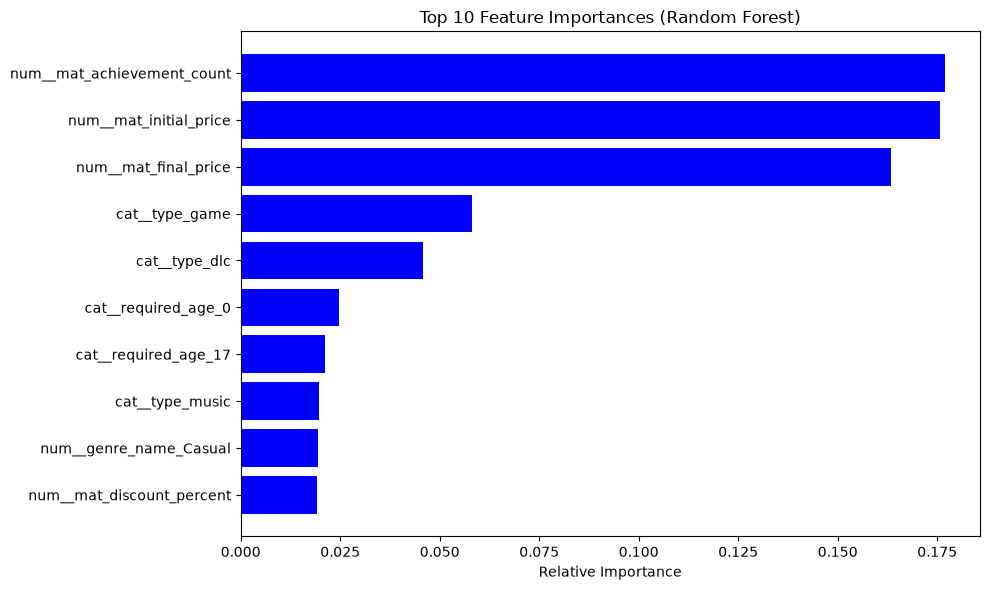

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Fit the Random Forest model on the training data
rf_model.fit(X_train, y_train)

# Extract feature names from the preprocessor and importances from the classifier
feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()
importances = rf_model.named_steps['classifier'].feature_importances_

# Get the indices of the top 10 features
indices = np.argsort(importances)[-10:]

# Plot the feature importances
plt.figure(figsize=(10, 6))
plt.title("Top 10 Feature Importances (Random Forest)")
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.tight_layout()
plt.show()

### Feature Importance Analysis
The plot above shows the top 10 most important features used by the Random Forest after removing identifiers (like `appid` and `genre_id`) to prevent the model from simply memorizing specific game IDs.

* **Achievements & Price:** `mat_achievement_count`, `mat_initial_price`, and `mat_final_price` are by far the most dominant features. This suggests that a game's price point and the number of in-game achievements are strong signals for how it will be reviewed.
* **Application Type:** The model heavily relies on whether the application is a base `game` or a `dlc`.
* **Genres:** The `Casual` genre appears in the top 10, showing that specific genres do carry predictive weight.
* **Limitations:** Because tree-based models split data based on numerical thresholds, the model might be overfitting to very specific price points. Additionally, excluding the actual review text means we are only capturing surface-level metadata.

## 4. Error Analysis
We evaluate the best model (Random Forest) on the protected test set using a confusion matrix to see exactly where it fails.

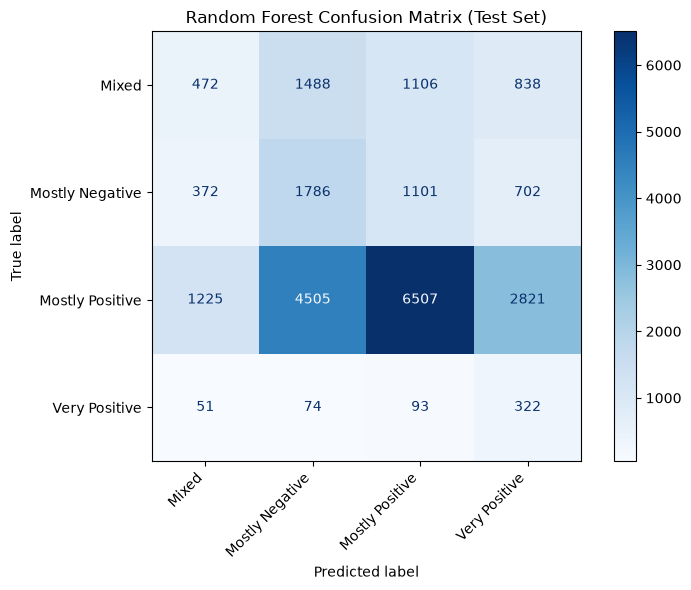

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

# Predict on the test set
y_pred_rf = rf_model.predict(X_test)

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_rf, 
    display_labels=rf_model.classes_, 
    cmap='Blues', 
    ax=ax
)
plt.title("Random Forest Confusion Matrix (Test Set)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Error Analysis
Looking at the Confusion Matrix for the Random Forest on the test set, we can identify exactly where the model struggles:

1. **The Minority Class Struggle:** The model performs worst on the "Very Positive" class. Out of all the true "Very Positive" games, it only correctly identified 322 of them. It frequently misclassified them as "Mostly Positive" (93 instances) or "Mostly Negative" (74 instances). 
2. **Majority Class Bias:** The model is heavily biased toward predicting "Mostly Positive" (the darkest blue column). Because "Mostly Positive" makes up 64.2% of the dataset, the model struggles to separate the nuanced boundaries between a "good" game and a "great" game. 
3. **Why does this happen?** This is a direct result of the severe class imbalance. Even with `class_weight='balanced'`, the Random Forest relies on metadata (price, achievements, genre) which often looks identical for a "Mostly Positive" and a "Very Positive" game. Without text-based review data, the model lacks the nuanced information needed to push a prediction into the highest rating tier.